# TGLF flux surrogate: training and evaluation

Trains surrogate models that predict three TGLF fluxes (ion heat flux Q_i, electron heat flux Q_e and electron particle flux Gamma_e) from the plasma inputs, using the 5,000-run `scan_db` table, then tests them on the 43 SAT3 cases. Three models (random forest, xgboost and a PyTorch neural network) are each tuned and trained twice: on the raw fluxes and on log(heat flux). Run the cells from top to bottom.

## Step 0: imports

numpy, pandas, matplotlib, scikit-learn, xgboost and PyTorch, plus `load_cases` from `tglf_dataset.py` to read SAT3. `RANDOM_STATE` fixes every random choice.

In [58]:
# step 0: import the necessary libraries

# data handling
import numpy as np
import pandas as pd
from pathlib import Path

# visualization
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.feature_selection import VarianceThreshold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.ensemble import IsolationForest

# model selection and evaluation
from sklearn.model_selection import train_test_split, GroupShuffleSplit, KFold, GridSearchCV, RandomizedSearchCV, cross_val_score, ParameterGrid, ParameterSampler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

# models
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# neural network (PyTorch)
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# SAT3 data
from tglf_dataset import letter_ion_case_info, load_cases  # reads every SAT3 case's input.tglf.gen + out.tglf.gbflux (tglf_dataset.py)

# utilities
import copy
import joblib
import warnings
from tqdm.auto import tqdm   # progress bars
import time

warnings.filterwarnings("ignore")

RANDOM_STATE = 42


## Step 1: load the data

Reads `data/scan_db_table.csv`: one row per scan run, with every TGLF input and the six output fluxes (particle, heat and momentum flux of the electrons and of the ion species). Only three of them are modelled (step 2.1); the other three are dropped, not used as inputs.

In [59]:
# step 1: import the data

df = pd.read_csv("data/scan_db_table.csv")

### 1.1 Distributions

A histogram of every input that varies and every flux (Figure 1), to check how the scan was sampled. The red line marks the most common value of each input.

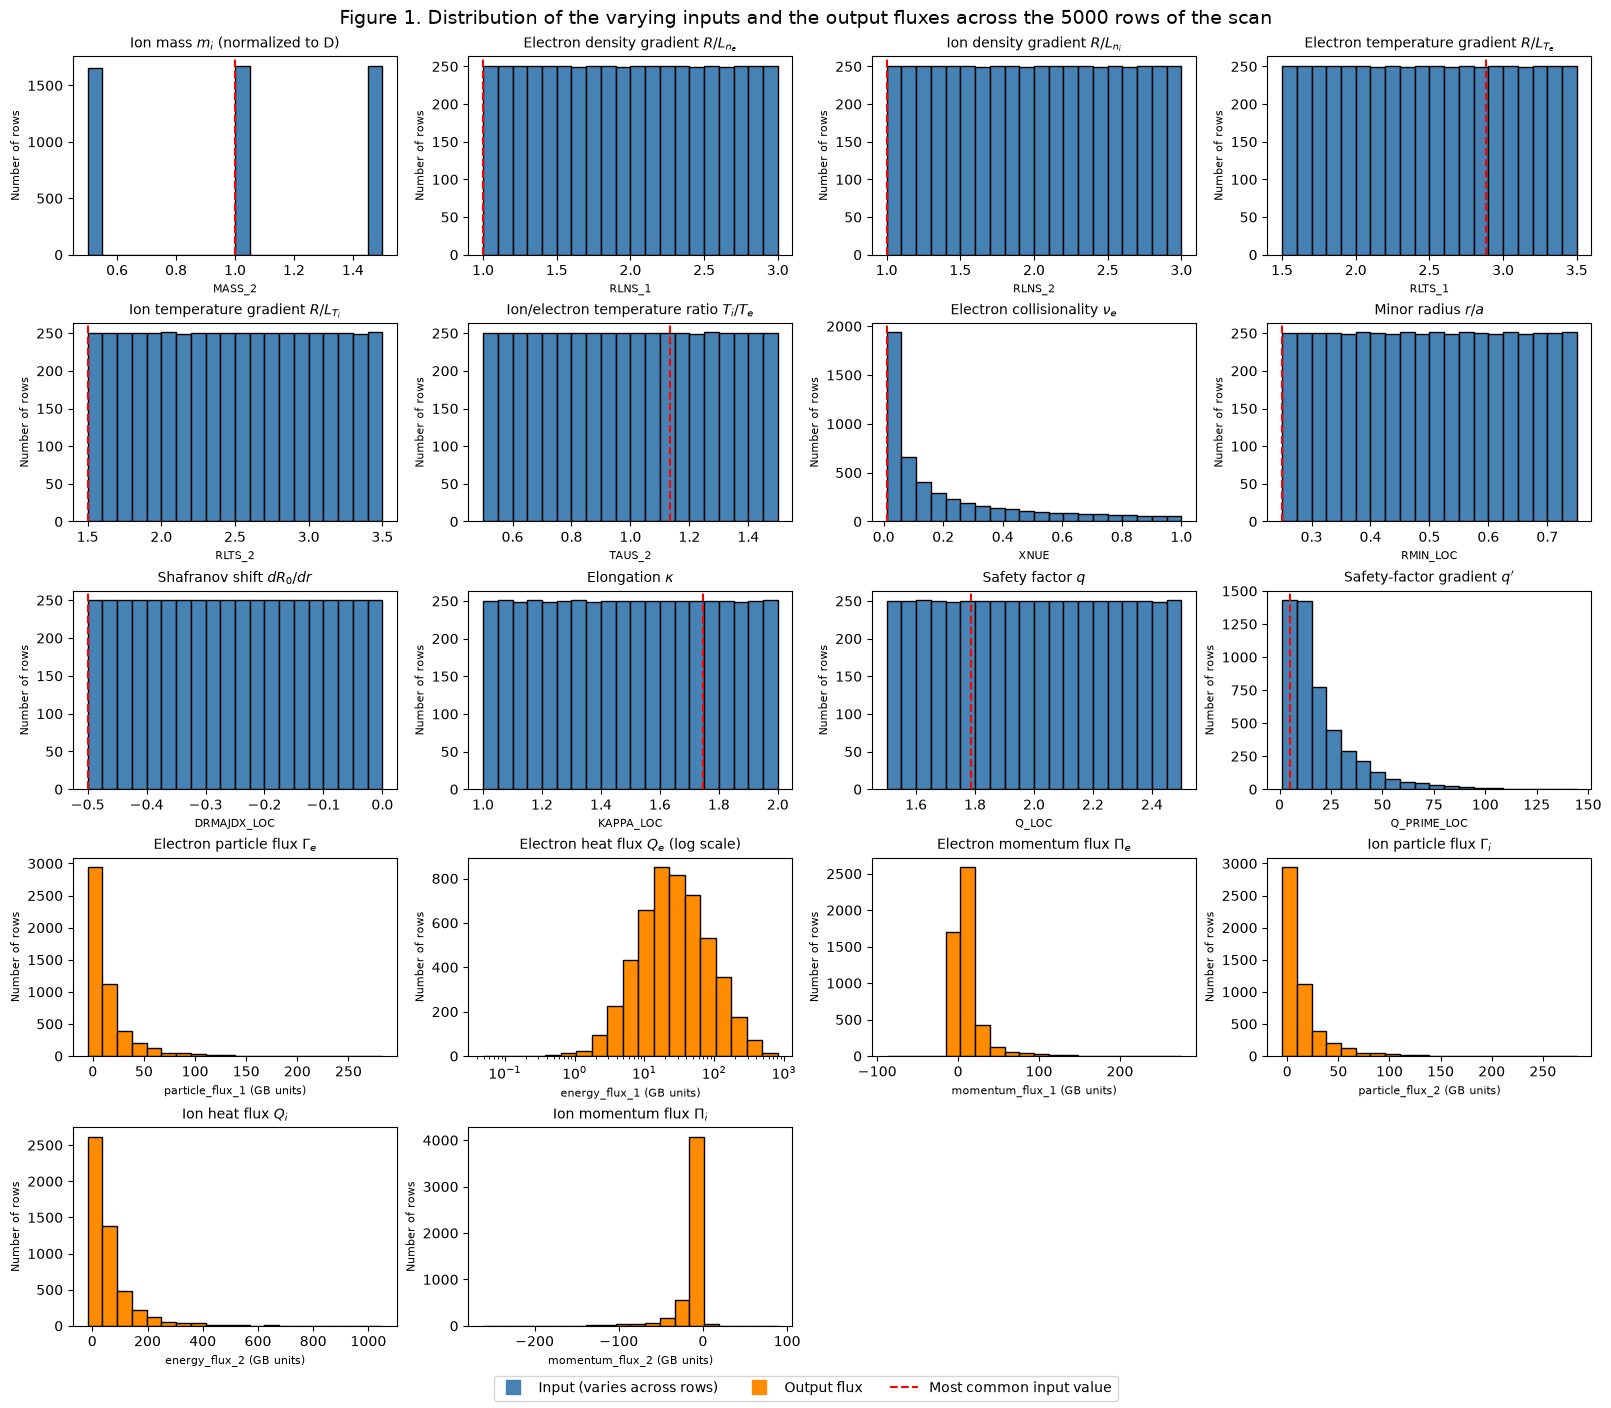

In [60]:
# step 1.1: plot histograms of every varying input and output flux to check how the scan was sampled (same logic as step 4.2 of sat3_tglf_flux_analysis.ipynb)
# fluxes are orange (inputs blue), energy fluxes get a log x-axis, and a red line marks the most common value of each input

FLUX_PREFIXES = ("particle_flux_", "energy_flux_", "momentum_flux_")
numeric_df = df.select_dtypes("number")
y_variables = [c for c in numeric_df.columns if c.startswith(FLUX_PREFIXES)]
x_variables = [c for c in numeric_df.columns if c not in y_variables and numeric_df[c].nunique() > 1]  # inputs that vary across rows
most_common = df[x_variables].mode().iloc[0]  # the most common value of each input column

# display names, so the plots use the same wording as the SAT3 notebook (fluxes are in gyro-Bohm (GB) units)
X_LABELS = {
    "MASS_2": r"Ion mass $m_i$ (normalized to D)",
    "RLTS_1": r"Electron temperature gradient $R/L_{T_e}$",
    "RLTS_2": r"Ion temperature gradient $R/L_{T_i}$",
    "RLNS_1": r"Electron density gradient $R/L_{n_e}$",
    "RLNS_2": r"Ion density gradient $R/L_{n_i}$",
    "TAUS_2": r"Ion/electron temperature ratio $T_i/T_e$",
    "XNUE": r"Electron collisionality $\nu_e$",
    "RMIN_LOC": r"Minor radius $r/a$",
    "DRMAJDX_LOC": r"Shafranov shift $dR_0/dr$",
    "KAPPA_LOC": r"Elongation $\kappa$",
    "Q_LOC": r"Safety factor $q$",
    "Q_PRIME_LOC": r"Safety-factor gradient $q'$",
}
FLUX_NAMES = {
    "particle_flux_1": r"Electron particle flux $\Gamma_e$",
    "particle_flux_2": r"Ion particle flux $\Gamma_i$",
    "energy_flux_1": r"Electron heat flux $Q_e$",
    "energy_flux_2": r"Ion heat flux $Q_i$",
    "momentum_flux_1": r"Electron momentum flux $\Pi_e$",
    "momentum_flux_2": r"Ion momentum flux $\Pi_i$",
}

cols = x_variables + y_variables
ncols = 4
nrows = int(np.ceil(len(cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 2.8 * nrows), constrained_layout=True)
for ax, col in zip(axes.flat, cols):
    s = df[col]
    is_flux = col.startswith(FLUX_PREFIXES)
    bins, log_axis = 20, col.startswith("energy_flux") and s.min() > 0
    if log_axis:
        bins = np.logspace(np.log10(s.min()), np.log10(s.max()), 20)  # equal-width bins on a log axis
        ax.set_xscale("log")
    ax.hist(s, bins=bins, color="darkorange" if is_flux else "steelblue", edgecolor="black")
    if col in most_common.index:
        ax.axvline(most_common[col], color="red", linestyle="--")
    ax.set_title(FLUX_NAMES.get(col, X_LABELS.get(col, col)) + (" (log scale)" if log_axis else ""), fontsize=10)
    ax.set_xlabel(f"{col} (GB units)" if is_flux else col, fontsize=8)
    ax.set_ylabel("Number of rows", fontsize=8)
for ax in axes.flat[len(cols):]:
    ax.axis("off")
fig.legend(handles=[
    plt.Line2D([], [], color="steelblue", marker="s", linestyle="", markersize=10, label="Input (varies across rows)"),
    plt.Line2D([], [], color="darkorange", marker="s", linestyle="", markersize=10, label="Output flux"),
    plt.Line2D([], [], color="red", linestyle="--", label="Most common input value"),
], loc="outside lower center", ncol=3)
fig.suptitle(f"Figure 1. Distribution of the varying inputs and the output fluxes across the {len(df)} rows of the scan", fontsize=14)
plt.show()

## Step 2: preprocess the data

Splits the rows 70/15/15 into train, validation and test sets, drops all six output fluxes from the inputs, keeps three as targets (Q_i, Q_e, Gamma_e), and cleans the inputs. The ion species label is dropped because MASS_2 already encodes it. Every statistic (correlations, variances, the scaler) comes from the training set only. Order: encode, drop invalid rows, drop correlated features, drop low-variance features, scale, then build the log targets.

In [61]:
# step 2: preprocess the data
# order matters: encode -> drop invalid rows -> drop correlated -> drop low variance (both on unscaled data) -> scale last, so the variance filter is meaningful

# step 2.0: train, validation, and test split -> 70, 15, 15 split (random and shuffled: every scan run is its own case, so no case is split across the sets)

train_val_df, test_df = train_test_split(df, test_size=0.15, random_state=RANDOM_STATE, shuffle=True, stratify=None)
train_df, val_df = train_test_split(train_val_df, test_size=0.1765, random_state=RANDOM_STATE, shuffle=True, stratify=None)  # 0.1765 * 0.85 ≈ 0.15

# step 2.1: remove output columns from the input dataframes for preprocessing (we don't want to use the outputs as inputs for the model)

ALL_FLUX_COLS = y_variables  # the six output fluxes defined in step 1.1; none of them may be an input
OUTPUT_COLS = ["energy_flux_2", "energy_flux_1", "particle_flux_1"]  # the three targets: Q_i, Q_e, Gamma_e (same as TGLF-Surrogate)
train_X_df, val_X_df, test_X_df = [df.drop(columns=ALL_FLUX_COLS) for df in (train_df, val_df, test_df)]
train_y_df, val_y_df, test_y_df = [df[OUTPUT_COLS] for df in (train_df, val_df, test_df)]

# step 2.2: categorical variable encoding

def encode_categoricals(df, drop_cols=('case', 'UNITS', 'species_type_2')):  # species_type_2 is redundant: MASS_2 already encodes the ion species numerically
    """Drop the non-informative columns, convert boolean (True / False) columns to numeric (1 / 0),
    then one-hot encode (drop='first') the remaining object columns.
    Returns the new dataframe (categorical columns replaced by their encoded versions) and the fitted encoder (None if nothing to encode).
    Does not modify the input dataframe, and is a no-op on a dataframe that has no categorical columns left."""
    df = df.drop(columns=list(drop_cols), errors='ignore') # drop non-informative categorical features
    df = df.astype({c: int for c in df.select_dtypes(include='bool').columns}) # boolean -> numeric, since numpy cannot subtract booleans (needed by the variance step)
    categorical_features = df.select_dtypes(include=['object']).columns.tolist() # compute AFTER the drop
    if not categorical_features:
        return df, None
    onehot_encoder = OneHotEncoder(drop='first', sparse_output=False)
    df_encoded = pd.DataFrame(
        onehot_encoder.fit_transform(df[categorical_features]),
        columns=onehot_encoder.get_feature_names_out(categorical_features),
        index=df.index,
    )
    return pd.concat([df.drop(columns=categorical_features), df_encoded], axis=1), onehot_encoder # replace the original categorical columns with their encoded versions

train_X_df, val_X_df, test_X_df = [encode_categoricals(df)[0] for df in (train_X_df, val_X_df, test_X_df)]  # encode categoricals in all splits

# step 2.3: remove invalid rows (not statistical outliers: large fluxes are real physics, so those stay)
# a row is invalid if any value is NaN / infinite or a heat flux is <= 0 (unphysical, and log(energy_flux) is undefined).
# the rule uses no training statistics, so it is applied to every split without leaking anything; X and y are filtered together to stay aligned

ENERGY_COLS = [c for c in OUTPUT_COLS if c.startswith("energy_flux")]

def valid_rows(X, y):
    return np.isfinite(X.select_dtypes("number")).all(axis=1) & np.isfinite(y).all(axis=1) & (y[ENERGY_COLS] > 0).all(axis=1)

for name, X, y in (("train", train_X_df, train_y_df), ("val", val_X_df, val_y_df), ("test", test_X_df, test_y_df)):
    print(f"{name}: dropping {(~valid_rows(X, y)).sum()} invalid rows of {len(X)}")
train_mask, val_mask, test_mask = valid_rows(train_X_df, train_y_df), valid_rows(val_X_df, val_y_df), valid_rows(test_X_df, test_y_df)
train_X_df, train_y_df = train_X_df[train_mask], train_y_df[train_mask]
val_X_df, val_y_df = val_X_df[val_mask], val_y_df[val_mask]
test_X_df, test_y_df = test_X_df[test_mask], test_y_df[test_mask]

# step 2.4: remove highly correlated features (correlation does not depend on scaling, so this runs on the raw values; statistics come from the training set only)

corr_matrix = train_X_df.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_features = [column for column in upper_tri.columns if any(upper_tri[column] > 0.9)]  # threshold for high correlation
high_corr_features_df = pd.DataFrame({
    'feature1': high_corr_features,
    'feature2': [upper_tri[column].idxmax() for column in high_corr_features],
    'max_correlation': [upper_tri[column].max() for column in high_corr_features]
})
high_corr_features_df.sort_values(by='max_correlation', ascending=False, inplace=True)
train_X_df, val_X_df, test_X_df = [df.drop(columns=high_corr_features) for df in (train_X_df, val_X_df, test_X_df)]  # same columns dropped from every split

# step 2.5: remove low variance features
# raw variance depends on each feature's units, so compare features on a common footing: variance after min-max scaling to [0, 1] (training set)

feature_range = train_X_df.max() - train_X_df.min()
minmax_variance = ((train_X_df - train_X_df.min()) / feature_range.replace(0, np.nan)).var().fillna(0)  # constant columns (range 0) get variance 0
low_variance_features = minmax_variance.index[minmax_variance < 0.01].tolist()  # threshold for low variance
low_variance_features_df = pd.DataFrame({'feature': low_variance_features, 'variance': minmax_variance[low_variance_features]})
low_variance_features_df.sort_values(by='variance', ascending=True, inplace=True)
train_X_df, val_X_df, test_X_df = [df.drop(columns=low_variance_features) for df in (train_X_df, val_X_df, test_X_df)]  # same columns dropped from every split

# step 2.6: feature scaling via standardization (last, so it cannot hide differences in variance from step 2.5)

def scale_features(train_X_df, val_X_df, test_X_df):
    """Standardize the continuous features (zero mean, unit variance) using the training set statistics.
    One-hot (0/1) columns are left as they are. Returns the three scaled dataframes and the fitted scaler."""
    binary_cols = [c for c in train_X_df.columns if set(train_X_df[c].unique()) <= {0, 1}]
    continuous_cols = [c for c in train_X_df.columns if c not in binary_cols]
    scaler = StandardScaler().fit(train_X_df[continuous_cols])
    scaled = []
    for df in (train_X_df, val_X_df, test_X_df):
        df = df.copy()
        df[continuous_cols] = scaler.transform(df[continuous_cols])
        scaled.append(df)
    return (*scaled, scaler)

train_X_scaled, val_X_scaled, test_X_scaled, scaler = scale_features(train_X_df, val_X_df, test_X_df)

# step 2.7: log targets, so models can be trained on both the raw fluxes and log(energy_flux)
# only the heat fluxes are always positive (checked in step 2.3), so only those get a log; particle flux can be negative and stays raw
# predictions from a log model are converted back with np.exp(pred) to compare with the raw-target models

def log_targets(y_df):
    y_log = y_df.copy()
    y_log[ENERGY_COLS] = np.log(y_df[ENERGY_COLS])   # natural log
    return y_log.rename(columns={c: f"log_{c}" for c in ENERGY_COLS})

train_y_log_df, val_y_log_df, test_y_log_df = [log_targets(y) for y in (train_y_df, val_y_df, test_y_df)]
# raw targets: train_y_df / val_y_df / test_y_df;  log targets: train_y_log_df / val_y_log_df / test_y_log_df

train: dropping 4 invalid rows of 3499
val: dropping 0 invalid rows of 751
test: dropping 0 invalid rows of 750


## Step 3: models and training

### 3.1 to 3.4 Definitions

The three models share one interface (`fit` and `predict`), so one cross-validation function and one grid search serve all of them. Nothing is trained in this cell.

In [62]:
# step 3: build the models and the tuning helpers (nothing is trained in this cell; step 3.5 runs everything)
# all three models share the same interface (make_model(**params) -> object with fit / predict), so one cross-validation function and one tuning function serve them all

# step 3.1: random forest (grid search over the number of trees, max depth and minimum leaf size)

def make_rf(**params):
    return RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **params)

rf_grid = {
    "n_estimators": [100, 300],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 3],
}

# step 3.2: xgboost (grid search over the number of trees, max depth, learning rate and subsample ratio)

def make_xgb(**params):
    return XGBRegressor(random_state=RANDOM_STATE, objective="reg:squarederror", n_jobs=-1, **params)

xgb_grid = {
    "n_estimators": [200, 500],
    "max_depth": [3, 6, 9],
    "learning_rate": [0.03, 0.1],
    "subsample": [0.7, 1.0],
}

# step 3.3: pyTorch neural network (grid search over the number of layers, neurons per layer, dropout, learning rate, weight decay and batch size)

class MLP(nn.Module):
    def __init__(self, in_dim, out_dim, hidden_dim=64, num_layers=2, dropout=0.1):
        super().__init__()
        layers = []
        for i in range(num_layers):
            layers += [nn.Linear(in_dim if i == 0 else hidden_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout)]
        layers.append(nn.Linear(hidden_dim, out_dim))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


class TorchMLPRegressor:
    """Wraps MLP in the same fit / predict interface as the sklearn models.
    Standardizes the targets (they differ a lot in magnitude), trains with Adam, and stops early on an internal 10% hold-out
    taken from the data it is given, so a cross-validation fold never leaks into its own early stopping."""

    def __init__(self, hidden_dim=64, num_layers=2, dropout=0.1, lr=1e-3, weight_decay=0.0, batch_size=64, max_epochs=300, patience=20):
        self.hidden_dim, self.num_layers, self.dropout = hidden_dim, num_layers, dropout
        self.lr, self.weight_decay, self.batch_size = lr, weight_decay, batch_size
        self.max_epochs, self.patience = max_epochs, patience

    def fit(self, X, y):
        torch.manual_seed(RANDOM_STATE)
        X, y = np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)
        self.y_mean_, self.y_std_ = y.mean(axis=0), y.std(axis=0)
        y = (y - self.y_mean_) / self.y_std_
        X_fit, X_stop, y_fit, y_stop = [torch.from_numpy(a) for a in train_test_split(X, y, test_size=0.1, random_state=RANDOM_STATE)]
        loader = DataLoader(TensorDataset(X_fit, y_fit), batch_size=self.batch_size, shuffle=True)

        self.model_ = MLP(X.shape[1], y.shape[1], self.hidden_dim, self.num_layers, self.dropout)
        optimizer = torch.optim.Adam(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        loss_fn = nn.MSELoss()

        best_loss, best_state, epochs_without_improvement = float("inf"), None, 0
        for _ in range(self.max_epochs):
            self.model_.train()
            for X_batch, y_batch in loader:
                optimizer.zero_grad()
                loss_fn(self.model_(X_batch), y_batch).backward()
                optimizer.step()

            self.model_.eval()
            with torch.no_grad():
                stop_loss = loss_fn(self.model_(X_stop), y_stop).item()
            if stop_loss < best_loss:
                best_loss, best_state, epochs_without_improvement = stop_loss, copy.deepcopy(self.model_.state_dict()), 0  # deepcopy: state_dict() alone is a live reference
            else:
                epochs_without_improvement += 1
                if epochs_without_improvement >= self.patience:
                    break
        self.model_.load_state_dict(best_state)
        return self

    def predict(self, X):
        self.model_.eval()
        with torch.no_grad():
            pred = self.model_(torch.from_numpy(np.asarray(X, dtype=np.float32))).numpy()
        return pred * self.y_std_ + self.y_mean_   # back to the original units


def make_mlp(**params):
    return TorchMLPRegressor(**params)

mlp_grid = {
    "hidden_dim": [32, 64, 128],
    "num_layers": [2, 3],
    "dropout": [0.0, 0.1],
    "lr": [1e-3, 3e-3],
    "weight_decay": [0.0, 1e-4],
    "batch_size": [64],
}

# step 3.4: cross-validation and grid search, shared by every model

def nrmse(y_true, y_pred, y_std):
    """RMSE of each target in units of that target's standard deviation, averaged over the targets.
    Without this, the targets with the largest magnitude would dominate any score that averages over all of them."""
    return float(np.sqrt((((np.asarray(y_true) - y_pred) / y_std) ** 2).mean(axis=0)).mean())


def cv_score(make_model, params, X, y, n_splits=5):
    """Mean normalized RMSE of one hyperparameter setting over a k-fold split of the training set."""
    X, y = np.asarray(X), np.asarray(y)
    scores = []
    for fit_idx, score_idx in KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE).split(X):
        model = make_model(**params).fit(X[fit_idx], y[fit_idx])
        scores.append(nrmse(y[score_idx], model.predict(X[score_idx]), y[fit_idx].std(axis=0)))
    return float(np.mean(scores))


def tune(name, make_model, grid, X, y, max_combos=None):
    """Grid search with a progress bar. If the grid has more than max_combos settings, a random sample of max_combos is tried instead.
    Returns the best parameters, a table of every setting's CV score, and the best model refit on all of X."""
    combos = list(ParameterGrid(grid))
    if max_combos and len(combos) > max_combos:
        combos = list(ParameterSampler(grid, n_iter=max_combos, random_state=RANDOM_STATE))
    scores = [cv_score(make_model, p, X, y) for p in tqdm(combos, desc=f"{name}: grid search", leave=False)]
    results = pd.DataFrame(combos).assign(cv_nrmse=scores).sort_values("cv_nrmse").reset_index(drop=True)
    best_params = combos[int(np.argmin(scores))]
    return best_params, results, make_model(**best_params).fit(X, y)


### 3.5 Tune all models

A grid search with 5-fold cross-validation for each model on both target sets, six combinations in all. Table 1 gives the best settings and the validation scores.

In [63]:
# step 3.5: tune and train every model on both target sets (raw fluxes and log(energy_flux)), with progress bars
# the neural network grid is large, so by default a random sample of MLP_MAX_COMBOS settings is tried (set it to None for the full grid)

MLP_MAX_COMBOS = 16

TARGET_SETS = {   # name -> (train targets, validation targets)
    "raw": (train_y_df, val_y_df),
    "log": (train_y_log_df, val_y_log_df),
}
MODELS = {        # name -> (make_model, grid, max_combos)
    "random forest": (make_rf, rf_grid, None),
    "xgboost": (make_xgb, xgb_grid, None),
    "neural network": (make_mlp, mlp_grid, MLP_MAX_COMBOS),
}


def to_raw_units(pred, columns):
    """Undo the log on the heat fluxes, so predictions from the log-target models are scored on the same raw targets as the others."""
    pred = pd.DataFrame(pred, columns=columns)
    for c in ENERGY_COLS:
        if f"log_{c}" in pred:
            pred[c] = np.exp(pred.pop(f"log_{c}"))
    return pred[OUTPUT_COLS].to_numpy()


val_y_raw = val_y_df[OUTPUT_COLS].to_numpy()
train_y_std = train_y_df[OUTPUT_COLS].std(axis=0).to_numpy()

fitted_models, tuning_results, summary_rows = {}, {}, []
jobs = [(target_set, model_name) for target_set in TARGET_SETS for model_name in MODELS]
for target_set, model_name in tqdm(jobs, desc="all models"):
    y_train, _ = TARGET_SETS[target_set]
    make_model, grid, max_combos = MODELS[model_name]
    best_params, results, best_model = tune(f"{model_name} ({target_set} targets)", make_model, grid, train_X_scaled, y_train, max_combos)

    pred = to_raw_units(best_model.predict(val_X_scaled), y_train.columns)
    fitted_models[(model_name, target_set)] = best_model
    tuning_results[(model_name, target_set)] = results
    summary_rows.append({
        "model": model_name,
        "targets": target_set,
        "best params": best_params,
        "cv nrmse (own targets)": results["cv_nrmse"].iloc[0],
        "val nrmse (raw units)": nrmse(val_y_raw, pred, train_y_std),
        "val R2 (raw units)": r2_score(val_y_raw, pred),
    })

summary = pd.DataFrame(summary_rows).sort_values("val nrmse (raw units)").reset_index(drop=True)
# cv nrmse is measured on each model's own targets (raw or log), so only the validation columns compare raw-target and log-target models
print("Table 1. Best hyperparameters and validation scores for each model and target set (sorted by validation nRMSE; lower nRMSE and higher R2 are better).")
print("cv nrmse is scored on each model's own targets (raw or log); the val columns are in raw flux units, so only those compare raw-target and log-target models.")
summary


all models:   0%|          | 0/6 [00:00<?, ?it/s]

random forest (raw targets): grid search:   0%|          | 0/12 [00:00<?, ?it/s]

xgboost (raw targets): grid search:   0%|          | 0/24 [00:00<?, ?it/s]

neural network (raw targets): grid search:   0%|          | 0/16 [00:00<?, ?it/s]

random forest (log targets): grid search:   0%|          | 0/12 [00:00<?, ?it/s]

xgboost (log targets): grid search:   0%|          | 0/24 [00:00<?, ?it/s]

neural network (log targets): grid search:   0%|          | 0/16 [00:00<?, ?it/s]

Table 1. Best hyperparameters and validation scores for each model and target set (sorted by validation nRMSE; lower nRMSE and higher R2 are better).
cv nrmse is scored on each model's own targets (raw or log); the val columns are in raw flux units, so only those compare raw-target and log-target models.


,model,targets,best params,cv nrmse (own targets),val nrmse (raw units),val R2 (raw units)
0,neural network,raw,"{'weight_decay': 0.0, 'num_layers': 2, 'lr': 0...",0.372520,0.301458,0.921962
1,neural network,log,"{'weight_decay': 0.0001, 'num_layers': 3, 'lr'...",0.334758,0.325552,0.908981
2,xgboost,log,"{'learning_rate': 0.03, 'max_depth': 6, 'n_est...",0.394794,0.415545,0.850183
3,xgboost,raw,"{'learning_rate': 0.03, 'max_depth': 6, 'n_est...",0.440821,0.415844,0.849822
4,random forest,raw,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.581075,0.592261,0.696918
5,random forest,log,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.537130,0.608235,0.678293


### 3.6 Baseline

Ridge (linear) regression with a fixed setting, the simple model the tuned models have to beat. It is scored like the other models and appears as the "ridge baseline" in Tables 3 and 4 and in Figures 2 to 4.

In [85]:
# step 3.6: baseline model (ridge regression), the simple linear model the tuned models have to beat

def make_ridge(**params):
    return Ridge(alpha=1.0, random_state=RANDOM_STATE, **params)   # fixed setting, nothing to tune

baseline_rows = []
for target_set, (y_train, y_val) in TARGET_SETS.items():
    model = make_ridge().fit(train_X_scaled, y_train)
    pred = to_raw_units(model.predict(val_X_scaled), y_train.columns)   # predictions from the log targets are converted back to raw units
    baseline_rows.append({
        "model": "ridge baseline",
        "targets": target_set,
        "best params": {"alpha": 1.0},
        "val nrmse (raw units)": nrmse(val_y_raw, pred, train_y_std),
        "val R2 (raw units)": r2_score(val_y_raw, pred),
    })

baseline_scores = pd.DataFrame(baseline_rows)   # the test scores are added in step 3.9; the baseline then appears in Tables 3 and 4 and in Figures 2 to 4
print("Validation scores of the ridge baseline (fit on the training set, scored in raw flux units).")
baseline_scores


Validation scores of the ridge baseline (fit on the training set, scored in raw flux units).


,model,targets,best params,val nrmse (raw units),val R2 (raw units)
0,ridge baseline,raw,{'alpha': 1.0},0.822500,0.420515
1,ridge baseline,log,{'alpha': 1.0},0.758974,0.498221


### 3.7 Speed

Training time and prediction time per case for each model (Table 2), to compare with TGLF's seconds per case.

In [64]:
# step 3.7: time the training and prediction of each model on the validation set, both batched and one case at a time

def time_model(make_model, params, X_train, y_train, X_val, n_repeats=10, n_single=200):
    """Time one fit with the chosen settings, then predict on the validation set (per case, batched and one case at a time)."""
    X_eval = np.asarray(X_val)

    start = time.perf_counter()
    model = make_model(**params).fit(X_train, y_train)
    train_s = time.perf_counter() - start

    model.predict(X_eval[:1])   # warm-up call, so one-off setup cost is not counted

    batch = []
    for _ in range(n_repeats):
        start = time.perf_counter()
        model.predict(X_eval)
        batch.append(time.perf_counter() - start)

    single = []
    for row in X_eval[:n_single]:
        start = time.perf_counter()
        model.predict(row[None, :])
        single.append(time.perf_counter() - start)

    return {
        "train time (s)": train_s,
        "predict, batched (us per case)": np.median(batch) / len(X_eval) * 1e6,
        "predict, one case per call (us per case)": np.median(single) * 1e6,
    }

timing_rows = []
for _, row in tqdm(summary.iterrows(), total=len(summary), desc="timing"):
    make_model = MODELS[row["model"]][0]
    y_train, _ = TARGET_SETS[row["targets"]]
    timing_rows.append({"model": row["model"], "targets": row["targets"],
                        **time_model(make_model, row["best params"], train_X_scaled, y_train, val_X_scaled)})

timing = pd.DataFrame(timing_rows)
print("Table 2. Validation scores with training time and prediction time for each model and target set (one fit on the training set; prediction times are medians over repeated calls on the validation set).")
print("'batched' predicts the whole validation set in one call and divides by the number of cases; 'one case per call' predicts a single case at a time (1 us = 1e-6 s).")
summary.merge(timing, on=["model", "targets"])

timing:   0%|          | 0/6 [00:00<?, ?it/s]

Table 2. Validation scores with training time and prediction time for each model and target set (one fit on the training set; prediction times are medians over repeated calls on the validation set).
'batched' predicts the whole validation set in one call and divides by the number of cases; 'one case per call' predicts a single case at a time (1 us = 1e-6 s).


,model,targets,best params,cv nrmse (own targets),val nrmse (raw units),val R2 (raw units),train time (s),"predict, batched (us per case)","predict, one case per call (us per case)"
0,neural network,raw,"{'weight_decay': 0.0, 'num_layers': 2, 'lr': 0...",0.372520,0.301458,0.921962,17.055783,0.456791,175.499998
1,neural network,log,"{'weight_decay': 0.0001, 'num_layers': 3, 'lr'...",0.334758,0.325552,0.908981,7.023819,0.914913,229.650002
2,xgboost,log,"{'learning_rate': 0.03, 'max_depth': 6, 'n_est...",0.394794,0.415545,0.850183,4.768311,17.487417,4261.850001
3,xgboost,raw,"{'learning_rate': 0.03, 'max_depth': 6, 'n_est...",0.440821,0.415844,0.849822,4.637810,17.298003,4153.949994
4,random forest,raw,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.581075,0.592261,0.696918,1.158351,192.384487,75482.649991
5,random forest,log,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.537130,0.608235,0.678293,1.134878,178.574634,75099.049995


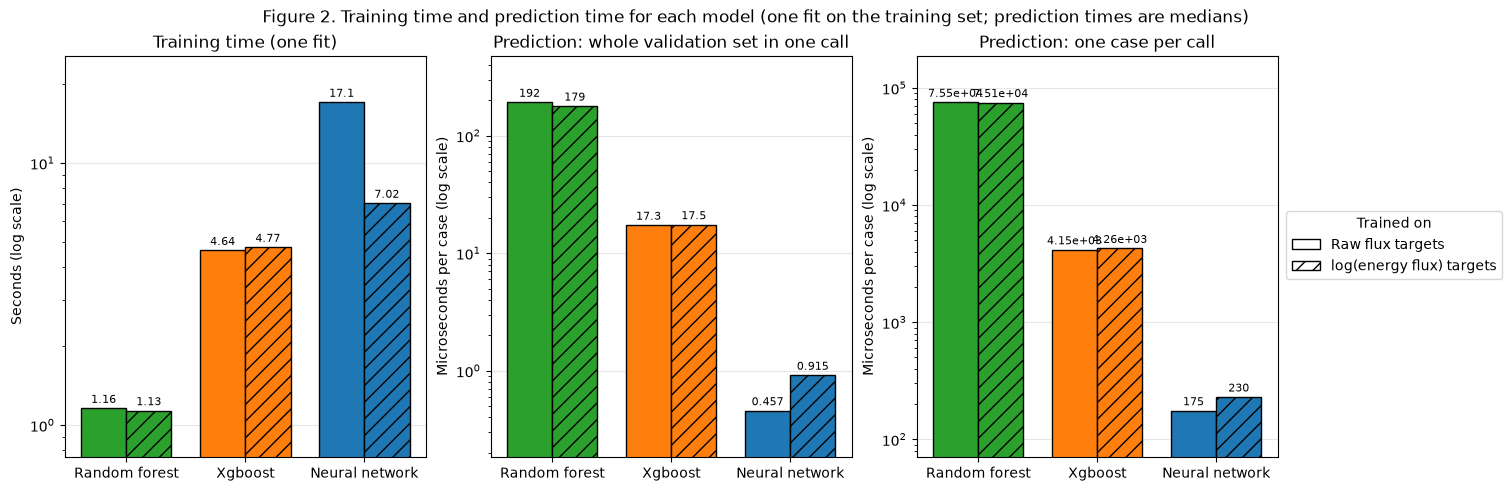

In [89]:
# step 3.7.1: plot the training and prediction times for each model and target set (one fit on the training set; prediction times are medians over repeated calls on the validation set)

timing_panels = {   # column in `timing` -> (panel title, y-axis label)
    "train time (s)": ("Training time (one fit)", "Seconds"),
    "predict, batched (us per case)": ("Prediction: whole validation set in one call", "Microseconds per case"),
    "predict, one case per call (us per case)": ("Prediction: one case per call", "Microseconds per case"),
}
model_names = list(MODELS)
x = np.arange(len(model_names))
width = 0.38

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), constrained_layout=True)
for ax, (column, (title, ylabel)) in zip(axes, timing_panels.items()):
    for offset, target_set, hatch in ((-width / 2, "raw", ""), (width / 2, "log", "//")):
        d = timing[timing["targets"] == target_set].set_index("model").loc[model_names]
        bars = ax.bar(x + offset, d[column], width, color=[MODEL_COLORS[m] for m in model_names], hatch=hatch, edgecolor="black")
        ax.bar_label(bars, fmt="%.3g", padding=2, fontsize=8)
    ax.set_yscale("log")                                     # the models differ by orders of magnitude
    ax.set_xticks(x, [m.capitalize() for m in model_names])
    ax.set_title(title)
    ax.set_ylabel(ylabel + " (log scale)")
    ax.grid(True, axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.margins(y=0.15)                                       # room above the bars for the value labels
fig.legend(handles=[
    plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor="black", label="Raw flux targets"),
    plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor="black", hatch="//", label="log(energy flux) targets"),
], title="Trained on", loc="outside right center")
fig.suptitle("Figure 2. Training time and prediction time for each model (one fit on the training set; prediction times are medians)")
plt.show()


### 3.8 Learning curves

Refits each tuned model on 250, 500, 1,000, 2,000 and all training cases, and plots the validation error against the training set size (Figure 2).

training sizes:   0%|          | 0/6 [00:00<?, ?it/s]

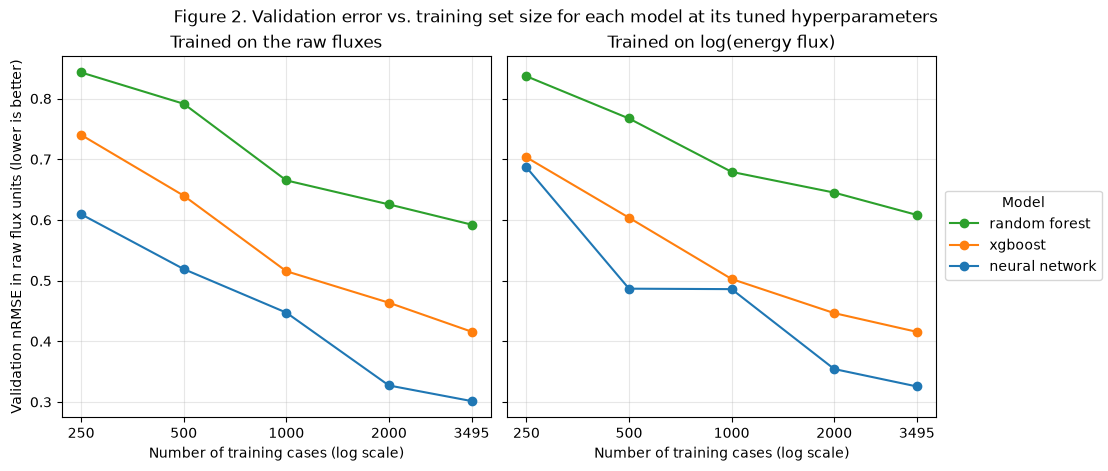

In [65]:
# step 3.8: run models on different training cases (250, 500, 1,000, 2,000 and all cases) and graph the validation nRMSE vs. training set size for each model and target set
# every model keeps the hyperparameters chosen in step 3.5, and each smaller training set is the first n rows of the next larger one (the split in step 2.0 is shuffled, so these are random subsets)

TRAIN_SIZES = [250, 500, 1000, 2000, len(train_X_scaled)]


def run_on_training_sizes(make_model, params, train_X, train_y, val_X, val_y, sizes):
    """Train and evaluate the model on different training set sizes, returning a dataframe of the results."""
    results = []
    for size in sizes:
        if size > len(train_X):
            continue
        X_subset, y_subset = train_X.iloc[:size], train_y.iloc[:size]   # train_y stays a dataframe: to_raw_units needs its column names to undo the log
        model = make_model(**params).fit(X_subset, y_subset)
        pred = to_raw_units(model.predict(val_X), y_subset.columns)
        results.append({
            "train_size": size,
            "val_nrmse": nrmse(val_y, pred, train_y_std),
            "val_r2": r2_score(val_y, pred),
        })
    return pd.DataFrame(results)


all_size_results = []
for _, row in tqdm(summary.iterrows(), total=len(summary), desc="training sizes"):
    make_model = MODELS[row["model"]][0]
    y_train = TARGET_SETS[row["targets"]][0]
    results = run_on_training_sizes(make_model, row["best params"], train_X_scaled, y_train, val_X_scaled, val_y_raw, TRAIN_SIZES)
    all_size_results.append(results.assign(model=row["model"], targets=row["targets"]))
for target_set in TARGET_SETS:   # the ridge baseline from step 3.6 on the same training sizes (it has no hyperparameters to tune)
    y_train = TARGET_SETS[target_set][0]
    results = run_on_training_sizes(make_ridge, {}, train_X_scaled, y_train, val_X_scaled, val_y_raw, TRAIN_SIZES)
    all_size_results.append(results.assign(model="ridge baseline", targets=target_set))
size_results = pd.concat(all_size_results, ignore_index=True)   # one row per model x target set x training size

# plot: one panel per target set, one line per model, same y-axis so the panels can be compared directly
MODEL_COLORS = {"random forest": "tab:green", "xgboost": "tab:orange", "neural network": "tab:blue", "ridge baseline": "tab:gray"}
TARGET_TITLES = {"raw": "Trained on the raw fluxes", "log": "Trained on log(energy flux)"}

fig, axes = plt.subplots(1, len(TARGET_SETS), figsize=(11, 4.6), sharey=True, constrained_layout=True)
for ax, target_set in zip(axes, TARGET_SETS):
    for model_name in [*MODELS, "ridge baseline"]:
        d = size_results[(size_results["model"] == model_name) & (size_results["targets"] == target_set)]
        ax.plot(d["train_size"], d["val_nrmse"], "o--" if model_name == "ridge baseline" else "o-", color=MODEL_COLORS[model_name], label=model_name)
    ax.set_xscale("log")
    ax.set_xticks(TRAIN_SIZES, [str(s) for s in TRAIN_SIZES])
    ax.minorticks_off()
    ax.set_title(TARGET_TITLES[target_set])
    ax.set_xlabel("Number of training cases (log scale)")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("Validation nRMSE in raw flux units (lower is better)")
fig.legend(handles=axes[0].get_lines(), title="Model", loc="outside right center")
fig.suptitle("Figure 2. Validation error vs. training set size for each model at its tuned hyperparameters (dashed: ridge baseline)")
plt.show()


### 3.9 Test set

Refits each tuned model on train + validation and scores it on the held-out scan test set (Table 3). The fitted models are reused for SAT3 and for the feature importance.

In [66]:
# step 3.9: evaluate all models on the test set, using the best hyperparameters found in step 3.5 and the full training set (train + val) to fit each model

final_models = {}   # the models fit on train + val, kept so step 4 can score them on SAT3
for _, row in tqdm(summary.iterrows(), total=len(summary), desc="test set evaluation"):
    make_model = MODELS[row["model"]][0]
    y_train = pd.concat(TARGET_SETS[row["targets"]], ignore_index=True)  # full training set: train + val
    model = make_model(**row["best params"]).fit(pd.concat([train_X_scaled, val_X_scaled], ignore_index=True), y_train)
    final_models[(row["model"], row["targets"])] = model
    pred = to_raw_units(model.predict(test_X_scaled), y_train.columns)
    summary.loc[_, "test nrmse (raw units)"] = nrmse(test_y_df[OUTPUT_COLS].to_numpy(), pred, train_y_std)
    summary.loc[_, "test R2 (raw units)"] = r2_score(test_y_df[OUTPUT_COLS].to_numpy(), pred)
    
# the ridge baseline from step 3.6, refit on train + val like the tuned models, so it sits in the same table
baseline_models, baseline_test = {}, {}
for target_set in TARGET_SETS:
    y_trainval = pd.concat(TARGET_SETS[target_set], ignore_index=True)
    baseline_models[target_set] = make_ridge().fit(pd.concat([train_X_scaled, val_X_scaled], ignore_index=True), y_trainval)
    pred = to_raw_units(baseline_models[target_set].predict(test_X_scaled), y_trainval.columns)
    baseline_test[target_set] = (nrmse(test_y_df[OUTPUT_COLS].to_numpy(), pred, train_y_std), r2_score(test_y_df[OUTPUT_COLS].to_numpy(), pred))
baseline_scores["test nrmse (raw units)"] = baseline_scores["targets"].map(lambda t: baseline_test[t][0])
baseline_scores["test R2 (raw units)"] = baseline_scores["targets"].map(lambda t: baseline_test[t][1])

results = pd.concat([summary, baseline_scores], ignore_index=True).sort_values("test nrmse (raw units)").reset_index(drop=True)
scan_test_scores = results[["model", "targets", "test nrmse (raw units)", "test R2 (raw units)"]]   # kept for the SAT3 comparison in step 4 (includes the baseline)
print("Table 3. Test-set scores for each model and target set, refit on train + validation with the best hyperparameters (sorted by test nRMSE; lower nRMSE and higher R2 are better). The ridge baseline is a fixed linear fit, so it has no cv score.")
results

test set evaluation:   0%|          | 0/6 [00:00<?, ?it/s]

Table 3. Test-set scores for each model and target set, refit on train + validation with the best hyperparameters (sorted by test nRMSE; lower nRMSE and higher R2 are better).


,model,targets,best params,cv nrmse (own targets),val nrmse (raw units),val R2 (raw units),test nrmse (raw units),test R2 (raw units)
0,neural network,log,"{'weight_decay': 0.0001, 'num_layers': 3, 'lr'...",0.334758,0.325552,0.908981,0.331107,0.888078
1,neural network,raw,"{'weight_decay': 0.0, 'num_layers': 2, 'lr': 0...",0.372520,0.301458,0.921962,0.363891,0.864940
2,xgboost,log,"{'learning_rate': 0.03, 'max_depth': 6, 'n_est...",0.394794,0.415545,0.850183,0.382054,0.850428
3,xgboost,raw,"{'learning_rate': 0.03, 'max_depth': 6, 'n_est...",0.440821,0.415844,0.849822,0.400263,0.836109
4,random forest,raw,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.581075,0.592261,0.696918,0.551242,0.688423
5,random forest,log,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.537130,0.608235,0.678293,0.553659,0.684709


## Step 4: evaluate on SAT3

SAT3 is the real test of whether the surrogates transfer: 43 cases from a different dataset. They go through the same preprocessing as the scan data with nothing refit, and are scored by the models from step 3.9. Table 4 puts the SAT3 scores next to the scan test set.

In [84]:
# step 4: evaluate the models on SAT3 (43 cases from a different dataset than the scan: the real test of whether the surrogate transfers)
# SAT3 goes through the same steps as the scan data in step 2, but nothing is refit: the columns kept and the scaler come from the training set, and the models are the ones fit in step 3.9

# step 4.1: load SAT3 in the same raw format as scan_db_table.csv, so the step 2 pipeline applies unchanged

SAT3_DIR = Path("SAT3_dataset/SAT3_dataset/data")
sat3_df, sat3_failures = load_cases(SAT3_DIR, case_info=letter_ion_case_info)   # same loader as sat3_tglf_flux_analysis.ipynb
print(f"parsed {len(sat3_df)} SAT3 cases, {len(sat3_failures)} failed")

# step 4.2: apply the preprocessing of step 2 (same order)

sat3_X_df = sat3_df.drop(columns=[*ALL_FLUX_COLS, "letter1", "letter2"])     # step 2.1: outputs (and the SAT3 experiment labels) are not inputs
sat3_y_df = sat3_df[OUTPUT_COLS]
sat3_X_df = encode_categoricals(sat3_X_df)[0]                              # step 2.2

invalid = ~valid_rows(sat3_X_df, sat3_y_df)                                # step 2.3: same validity rule as the training data
print(f"dropping {invalid.sum()} invalid SAT3 rows of {len(sat3_X_df)}")
sat3_X_df, sat3_y_df = sat3_X_df[~invalid], sat3_y_df[~invalid]

# steps 2.4 and 2.5: drop high_corr_features and low_variance_features. Keeping exactly the training columns, in the training order, does both
# (a one-hot column for an ion species that SAT3 lacks would be filled with 0; any other missing feature is an error)
sat3_X_df = sat3_X_df.drop(columns=high_corr_features + low_variance_features, errors='ignore')
sat3_X_df = sat3_X_df.reindex(columns=train_X_df.columns, fill_value=0)   # keep the training columns in the training order, filling any missing columns with 0

# scaling (as in step 2.6): scale with the scaler fit on the training set. scale_features is not called again, because that would refit the scaler on the 43 SAT3 cases
continuous_cols = list(scaler.feature_names_in_)
sat3_X_scaled = sat3_X_df.copy()
sat3_X_scaled[continuous_cols] = scaler.transform(sat3_X_scaled[continuous_cols])

# log targets (as in step 2.7), same as the training data
sat3_y_log_df = log_targets(sat3_y_df)

# step 4.3: score every final model on SAT3, in raw units like the other splits

sat3_preds, sat3_rows = {}, []
for _, row in tqdm(summary.iterrows(), total=len(summary), desc="SAT3 evaluation"):
    model_name, target_set = row["model"], row["targets"]
    model = final_models[(model_name, target_set)]
    pred = to_raw_units(model.predict(sat3_X_scaled), TARGET_SETS[target_set][0].columns)
    sat3_preds[(model_name, target_set)] = pd.DataFrame(pred, index=sat3_X_df.index, columns=OUTPUT_COLS)   # kept for the error analysis in step 5
    sat3_rows.append({
        "model": model_name,
        "targets": target_set,
        "sat3 nrmse (raw units)": nrmse(sat3_y_df.to_numpy(), pred, train_y_std),
        "sat3 R2 (raw units)": r2_score(sat3_y_df.to_numpy(), pred),
    })

for target_set in TARGET_SETS:   # the ridge baseline (fit in step 3.9), scored in the same way
    pred = to_raw_units(baseline_models[target_set].predict(sat3_X_scaled), TARGET_SETS[target_set][0].columns)
    sat3_preds[("ridge baseline", target_set)] = pd.DataFrame(pred, index=sat3_X_df.index, columns=OUTPUT_COLS)
    sat3_rows.append({
        "model": "ridge baseline",
        "targets": target_set,
        "sat3 nrmse (raw units)": nrmse(sat3_y_df.to_numpy(), pred, train_y_std),
        "sat3 R2 (raw units)": r2_score(sat3_y_df.to_numpy(), pred),
    })

sat3_results = pd.DataFrame(sat3_rows).merge(
    scan_test_scores, on=["model", "targets"]   # the scan test set, for comparison (Table 3, includes the baseline)
).sort_values("sat3 nrmse (raw units)").reset_index(drop=True)
print(f"Table 4. Scores on the {len(sat3_y_df)} SAT3 cases next to the scan test set, for each model and target set (sorted by SAT3 nRMSE; lower nRMSE and higher R2 are better).")
sat3_results

parsed 43 SAT3 cases, 0 failed
dropping 0 invalid SAT3 rows of 43


SAT3 evaluation:   0%|          | 0/6 [00:00<?, ?it/s]

Table 4. Scores on the 43 SAT3 cases next to the scan test set, for each model and target set (sorted by SAT3 nRMSE; lower nRMSE and higher R2 are better).


,model,targets,sat3 nrmse (raw units),sat3 R2 (raw units),test nrmse (raw units),test R2 (raw units)
0,neural network,log,0.075060,0.950562,0.331107,0.888078
1,neural network,raw,0.162926,0.757945,0.363891,0.864940
2,xgboost,log,0.235373,0.486159,0.382054,0.850428
3,xgboost,raw,0.298586,0.238587,0.400263,0.836109
4,random forest,log,0.367036,-0.195885,0.553659,0.684709
5,random forest,raw,0.468663,-0.898688,0.551242,0.688423


### 4.4 nRMSE on SAT3

nRMSE on the scan test set (faded bars) and on SAT3 (solid bars) for each model (Figure 3).

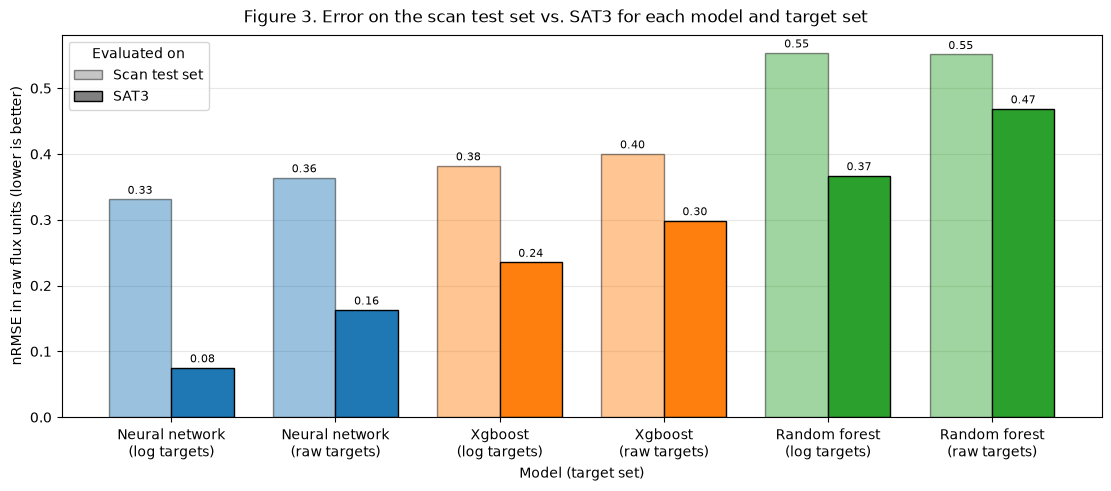

In [87]:
# step 4.4: plot the SAT3 NRMSE vs. the scan test set NRMSE for every model and target set, so the transferability of each model can be compared

# plot: SAT3 vs. scan test error for every model and target set (Table 4 as a chart)
labels = sat3_results["model"].str.capitalize() + "\n(" + sat3_results["targets"] + " targets)"
x = np.arange(len(sat3_results))
width = 0.38
colors = [MODEL_COLORS[m] for m in sat3_results["model"]]

fig, ax = plt.subplots(figsize=(11, 4.8), constrained_layout=True)
test_bars = ax.bar(x - width / 2, sat3_results["test nrmse (raw units)"], width, color=colors, alpha=0.45, edgecolor="black")
sat3_bars = ax.bar(x + width / 2, sat3_results["sat3 nrmse (raw units)"], width, color=colors, edgecolor="black")
for bars in (test_bars, sat3_bars):
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)   # print the value above each bar

ax.set_xticks(x, labels)
ax.set_xlabel("Model (target set)")
ax.set_ylabel("nRMSE in raw flux units (lower is better)")
ax.grid(True, axis="y", alpha=0.3)
ax.set_axisbelow(True)                                       # gridlines behind the bars
ax.legend(handles=[
    plt.Rectangle((0, 0), 1, 1, facecolor="grey", alpha=0.45, edgecolor="black", label="Scan test set"),
    plt.Rectangle((0, 0), 1, 1, facecolor="grey", edgecolor="black", label="SAT3"),
], title="Evaluated on", loc="upper left")
fig.suptitle("Figure 3. Error on the scan test set vs. SAT3 for each model and target set")
plt.show()


### 4.5 R2 on SAT3

The same comparison for R2 (Figure 4). R2 below 0 means worse than always predicting the mean.

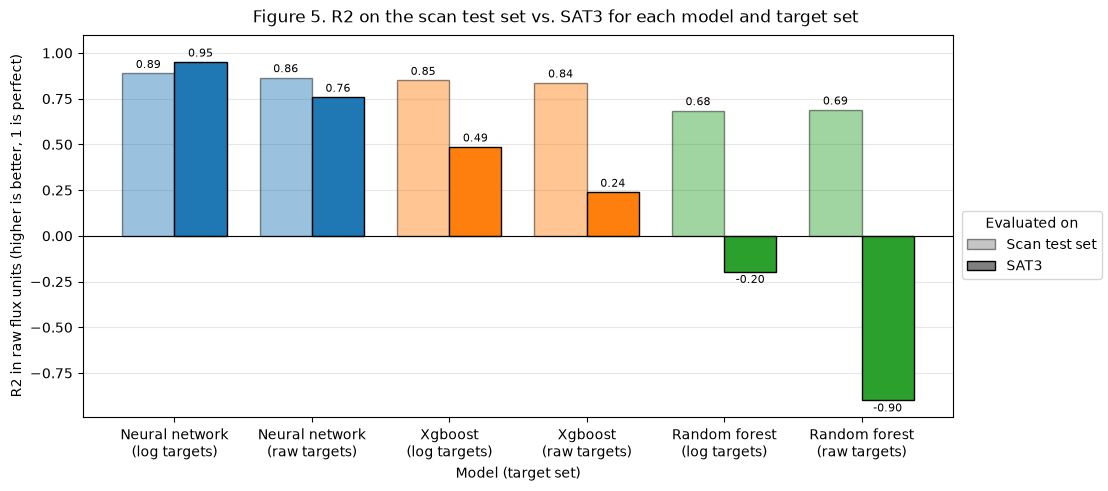

In [78]:
# step 4.5: plot the SAT3 R2 vs. the scan test set R2 for every model and target set, so the transferability of each model can be compared

# plot: the same comparison for R2 (same model order, colors and faded / solid bars as Figure 4)
fig, ax = plt.subplots(figsize=(11, 4.8), constrained_layout=True)
test_bars = ax.bar(x - width / 2, sat3_results["test R2 (raw units)"], width, color=colors, alpha=0.45, edgecolor="black")
sat3_bars = ax.bar(x + width / 2, sat3_results["sat3 R2 (raw units)"], width, color=colors, edgecolor="black")
for bars in (test_bars, sat3_bars):
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)

ax.axhline(0, color="black", linewidth=0.8)                  # R2 below 0 means worse than always predicting the mean
ax.set_ylim(top=1.1)                                         # room above R2 = 1 for the value labels
ax.set_xticks(x, labels)
ax.set_xlabel("Model (target set)")
ax.set_ylabel("R2 in raw flux units (higher is better, 1 is perfect)")
ax.grid(True, axis="y", alpha=0.3)
ax.set_axisbelow(True)
fig.legend(handles=[
    plt.Rectangle((0, 0), 1, 1, facecolor="grey", alpha=0.45, edgecolor="black", label="Scan test set"),
    plt.Rectangle((0, 0), 1, 1, facecolor="grey", edgecolor="black", label="SAT3"),
], title="Evaluated on", loc="outside right center")         # outside the axes, so it never covers bars of any height
fig.suptitle("Figure 4. R2 on the scan test set vs. SAT3 for each model and target set")
plt.show()


## Step 5: analyze the results

### 5.1 Feature importance

Which inputs the random forest and xgboost models rely on most (Table 5 and Figure 5), from the models fit on train + validation in step 3.9.

Table 5. Built-in feature importance of the tree models (each column sums to 1; a higher value means the trees relied on that feature more).


,random forest (raw targets),random forest (log targets),xgboost (raw targets),xgboost (log targets)
feature,,,,
MASS_2,0.004234,0.004583,0.018597,0.017519
RLNS_1,0.120409,0.194117,0.094286,0.151540
RLTS_1,0.031735,0.021031,0.029519,0.013395
RLTS_2,0.087317,0.071785,0.083032,0.066572
TAUS_2,0.087306,0.083298,0.089819,0.078100
XNUE,0.245976,0.212543,0.184242,0.179572
RMIN_LOC,0.130930,0.127090,0.143247,0.144528
DRMAJDX_LOC,0.085582,0.074379,0.109527,0.093758
KAPPA_LOC,0.078076,0.072722,0.094521,0.093545


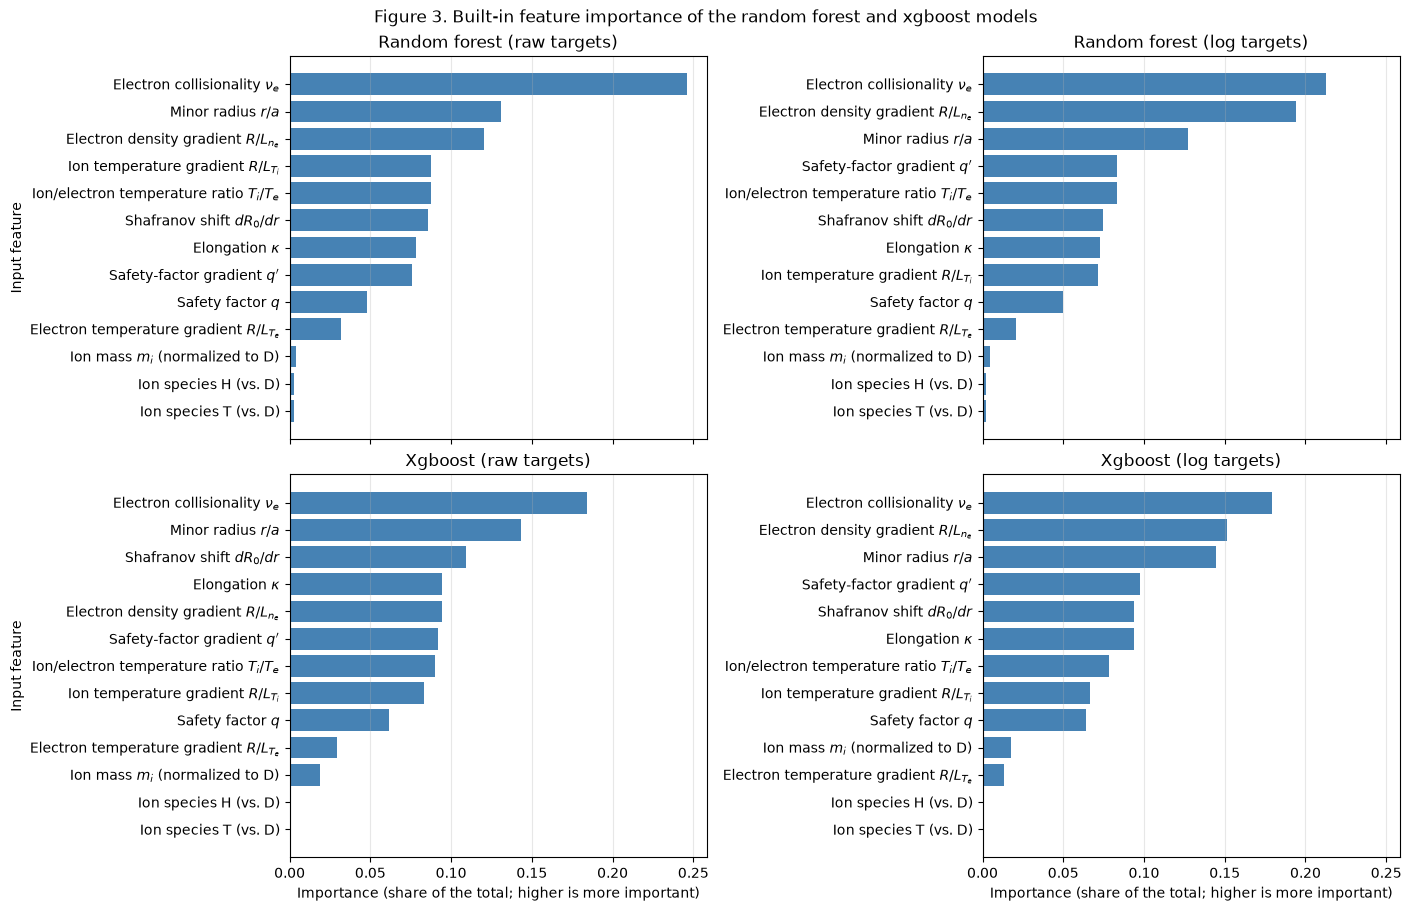

In [ ]:
# step 5: analyze the results (including feature importance, error analysis, etc.)

# step 5.1: built-in feature importance of the tree models (random forest and xgboost), from the models fit on train + val in step 3.9

all_importances = pd.DataFrame({
    f"{model_name} ({target_set} targets)": final_models[(model_name, target_set)].feature_importances_
    for model_name in ("random forest", "xgboost") for target_set in TARGET_SETS
}, index=train_X_scaled.columns).rename_axis("feature")

print("Table 5. Built-in feature importance of the tree models (each column sums to 1; a higher value means the trees relied on that feature more).")
display(all_importances)

IMPORTANCE_LABELS = {**X_LABELS, "species_type_2_H": "Ion species H (vs. D)", "species_type_2_T": "Ion species T (vs. D)"}   # readable feature names for the plot
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, constrained_layout=True)
for ax, name in zip(axes.flat, all_importances.columns):
    importances = all_importances[name].sort_values()   # ascending, so the most important feature is at the top of the bar chart
    ax.barh([IMPORTANCE_LABELS.get(f, f) for f in importances.index], importances.values, color="steelblue")
    ax.set_title(name[0].upper() + name[1:])
    ax.grid(True, axis="x", alpha=0.3)
for ax in axes[:, 0]:
    ax.set_ylabel("Input feature")
for ax in axes[1]:
    ax.set_xlabel("Importance (share of the total; higher is more important)")
fig.suptitle("Figure 5. Built-in feature importance of the random forest and xgboost models")
plt.show()
